# 12 -- Explainability

Weighted ensemble SHAP explanations consistent with the ensemble model used in evaluation and MRM.

## 1. Imports and setup

In [16]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import shap
import joblib
from pathlib import Path

import config
from src.explainability import (
    get_shap_values,
    plot_shap_summary,
    plot_shap_bar,
    plot_shap_waterfall,
    plot_shap_dependence,
)
from src.experiment import load_experiment_log

config.PLOTS_PATH.mkdir(parents=True, exist_ok=True)
config.RESULTS_PATH.mkdir(parents=True, exist_ok=True)

## 2. Load data and models

In [17]:
X_test = pd.read_parquet(config.RESULTS_PATH / 'X_test_selected.parquet')
y_test = pd.read_parquet(config.RESULTS_PATH / 'y_test.parquet').squeeze()

cat_final = joblib.load(config.OUTPUT_PATH / 'models' / 'catboost_final.pkl')
xgb_final = joblib.load(config.OUTPUT_PATH / 'models' / 'xgboost_final.pkl')
lgb_final = joblib.load(config.OUTPUT_PATH / 'models' / 'lightgbm_final.pkl')

print(f'X_test shape: {X_test.shape}')
print(f'fraud rate in test: {y_test.mean():.4f}')

X_test shape: (88581, 115)
fraud rate in test: 0.0348


In [19]:
# derive ensemble weights from experiment log (same method as notebook 09)
exp_log = load_experiment_log(config.RESULTS_PATH)

final_names = ['catboost_final', 'xgboost_final', 'lightgbm_final']
log_final = exp_log[exp_log['model'].isin(final_names)].copy()
log_final = log_final.drop_duplicates('model').set_index('model')

auc_vals = np.array([
    log_final.loc['catboost_final',  'metrics.val_auc'],
    log_final.loc['xgboost_final',   'metrics.val_auc'],
    log_final.loc['lightgbm_final',  'metrics.val_auc'],
])
raw_weights = auc_vals / auc_vals.sum()

weights = {
    'catboost_final':  float(raw_weights[0]),
    'xgboost_final':   float(raw_weights[1]),
    'lightgbm_final':  float(raw_weights[2]),
}

models = {
    'catboost_final':  cat_final,
    'xgboost_final':   xgb_final,
    'lightgbm_final':  lgb_final,
}

print('ensemble weights:')
for name, w in weights.items():
    print(f'  {name}: {w:.4f}')

ensemble weights:
  catboost_final: 0.3330
  xgboost_final: 0.3348
  lightgbm_final: 0.3322


## 3. Compute ensemble SHAP values

SHAP values are computed per model and blended using the same AUC-normalised weights as the ensemble score. This ensures feature importances reflect the ensemble's actual decision logic.

In [20]:
shap_values, X_sample, explainers = get_shap_values(
    models, weights, X_test, sample_n=2000
)

print(f'X_sample shape:    {X_sample.shape}')
print(f'shap_values shape: {shap_values.shape}')

mean_abs = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=X_sample.columns,
).sort_values(ascending=False)

print('\ntop 5 features by mean absolute ensemble SHAP:')
print(mean_abs.head(5).to_string())

X_sample shape:    (2000, 115)
shap_values shape: (2000, 115)

top 5 features by mean absolute ensemble SHAP:
C13               0.425417
C1                0.347434
D15               0.181301
C5                0.180993
TransactionAmt    0.179568


c:\Users\timot\fraud_model\fraud_model\fraud_env\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [21]:
shap_importance = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=X_sample.columns
).sort_values(ascending=False)

shap_importance.to_frame('shap_importance') \
    .reset_index() \
    .rename(columns={'index': 'feature'}) \
    .to_parquet(
        config.RESULTS_PATH / 'shap_importance.parquet',
        index=False
    )

print('shap importance saved')
print(shap_importance.head(10))

shap importance saved
C13                                    0.425417
C1                                     0.347434
D15                                    0.181301
C5                                     0.180993
TransactionAmt                         0.179568
card1__R_emaildomain__nunique          0.145137
M4_encoded                             0.144588
P_emaildomain__TransactionAmt__mean    0.143217
D1                                     0.139066
card1__TransactionAmt__mean            0.138759
dtype: float64


## 4. Global feature importance

### 4a. Beeswarm summary plot

Each dot is one observation. Colour = feature value (red high, blue low); x-position = ensemble SHAP contribution to fraud probability.

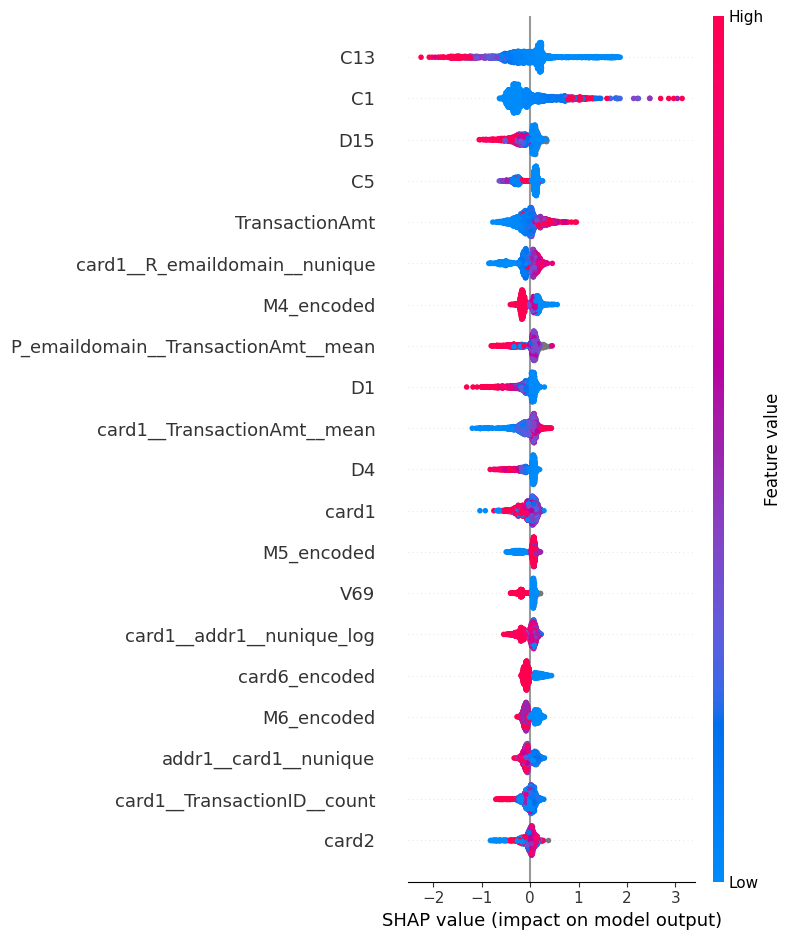

In [22]:
plot_shap_summary(
    shap_values,
    X_sample,
    output_path=config.PLOTS_PATH / 'shap_summary_ensemble.png',
)

### 4b. Mean absolute SHAP bar chart

Ranks features by average magnitude of their ensemble SHAP contribution across all sampled observations.

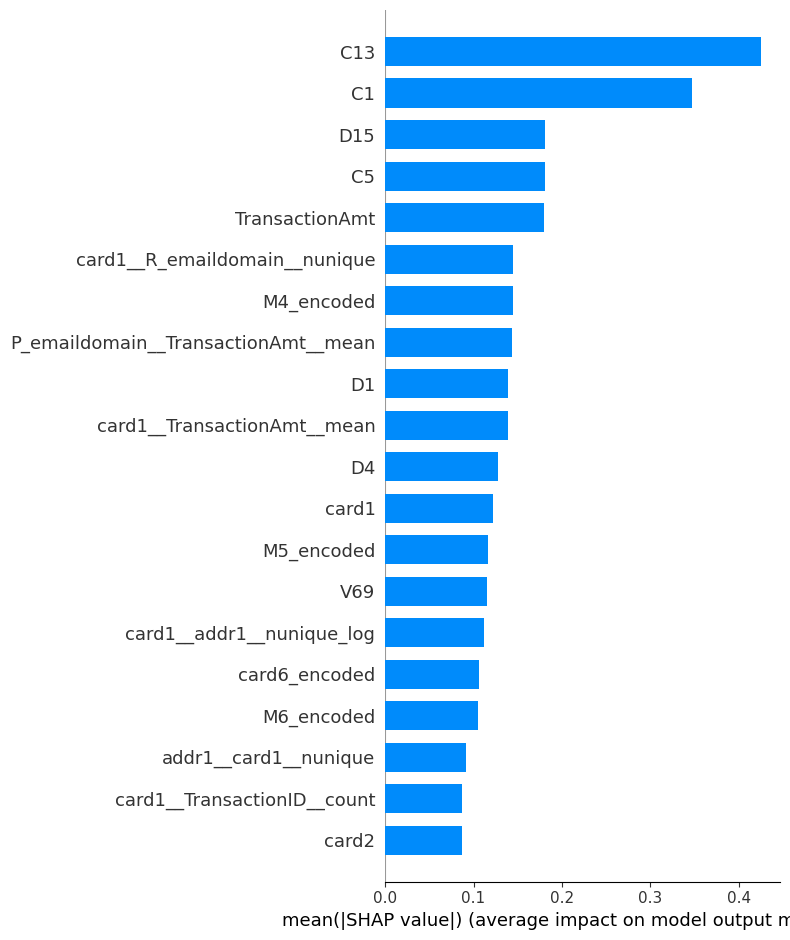

In [23]:
plot_shap_bar(
    shap_values,
    X_sample,
    output_path=config.PLOTS_PATH / 'shap_bar_ensemble.png',
)

## 5. Single prediction explanation (waterfall)

Waterfall charts decompose an individual transaction's score into per-feature contributions. XGBoost explainer is used here since waterfall requires a single Explanation object.

### 5a. Highest-scored true fraud

true fraud row index in X_sample: 101
xgboost predicted probability: 0.9993


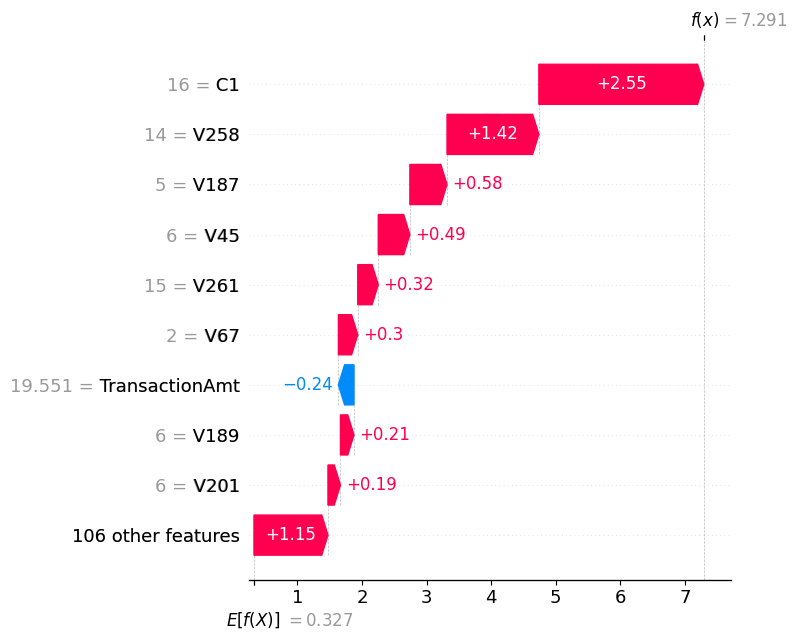

In [24]:
# score X_sample using xgboost (proxy for ensemble rank within the sample)
sample_proba = xgb_final.predict_proba(X_sample)[:, 1]
y_sample = y_test.loc[X_sample.index]

fraud_mask = (y_sample.values == 1)
if fraud_mask.sum() == 0:
    raise ValueError('no fraud cases in sample -- increase sample_n')

fraud_proba = np.where(fraud_mask, sample_proba, -1)
fraud_idx = int(np.argmax(fraud_proba))

print(f'true fraud row index in X_sample: {fraud_idx}')
print(f'xgboost predicted probability: {sample_proba[fraud_idx]:.4f}')

plot_shap_waterfall(
    explainers['xgboost_final'],
    X_sample,
    idx=fraud_idx,
    output_path=config.PLOTS_PATH / 'shap_waterfall_fraud_ensemble.png',
)

### 5b. Highest-scored false positive

false positive row index in X_sample: 60
xgboost predicted probability: 0.9782


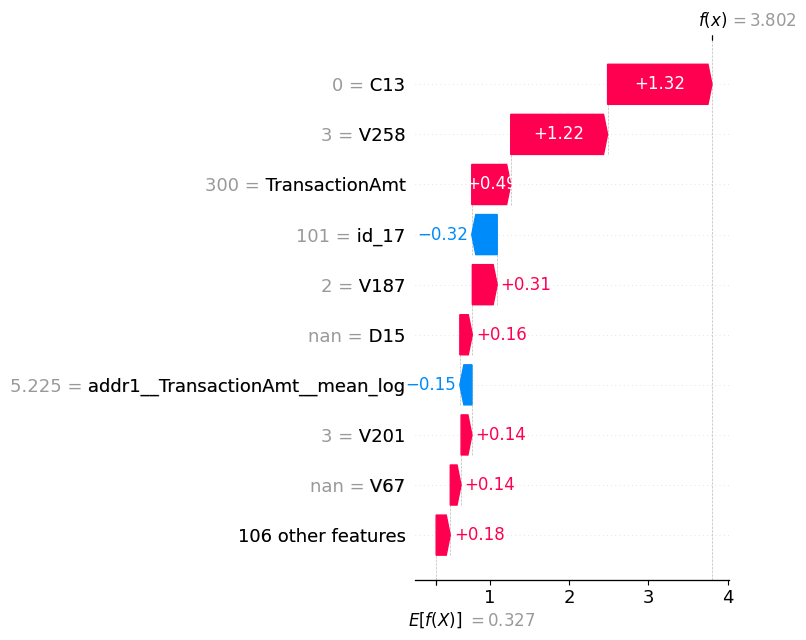

In [25]:
nonfrac_mask = (y_sample.values == 0)
nonfrac_proba = np.where(nonfrac_mask, sample_proba, -1)
fp_idx = int(np.argmax(nonfrac_proba))

print(f'false positive row index in X_sample: {fp_idx}')
print(f'xgboost predicted probability: {sample_proba[fp_idx]:.4f}')

plot_shap_waterfall(
    explainers['xgboost_final'],
    X_sample,
    idx=fp_idx,
    output_path=config.PLOTS_PATH / 'shap_waterfall_fp_ensemble.png',
)

## 6. Feature dependence plots

Shows the relationship between a feature's value and its ensemble SHAP contribution. Colour encodes an automatically chosen interaction feature.

In [26]:
mean_abs_shap = np.abs(shap_values).mean(axis=0)
top3_idx = np.argsort(mean_abs_shap)[::-1][:3]
top3_features = X_sample.columns[top3_idx].tolist()

print('top 3 features by ensemble mean absolute SHAP:', top3_features)

top 3 features by ensemble mean absolute SHAP: ['C13', 'C1', 'D15']


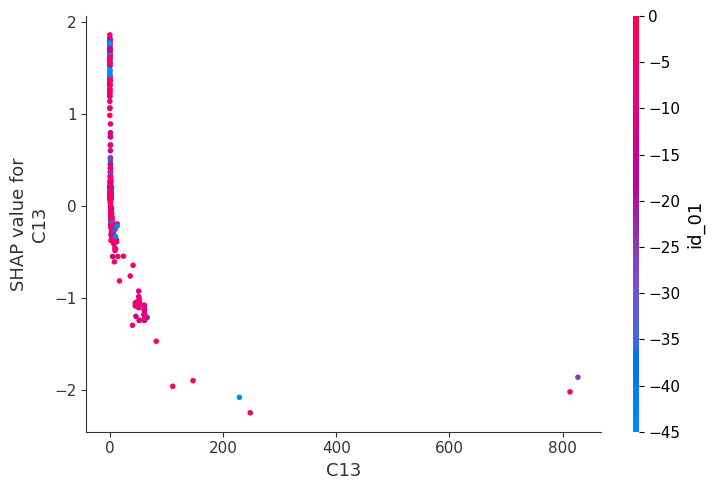

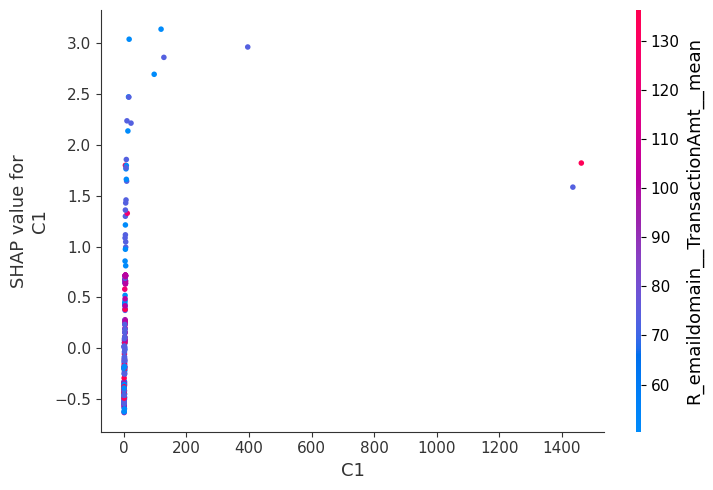

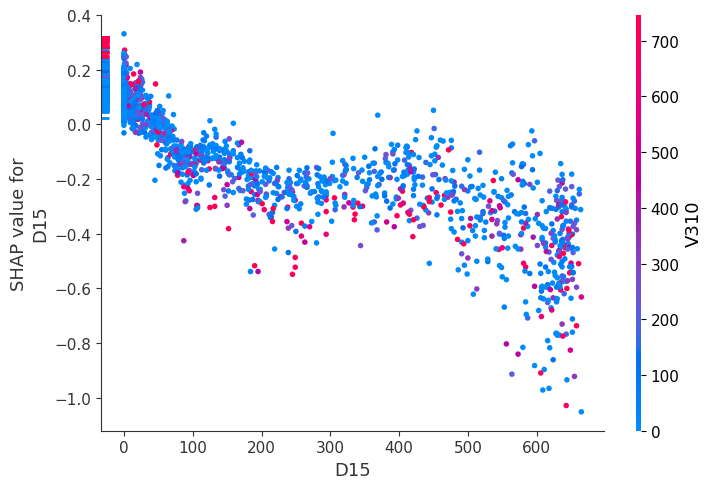

In [27]:
for feat in top3_features:
    plot_shap_dependence(
        shap_values,
        X_sample,
        feature=feat,
        output_path=config.PLOTS_PATH / f'shap_dependence_{feat}_ensemble.png',
    )

## 7. SHAP vs CatBoost importance comparison

Cross-validates the ensemble SHAP ranking against CatBoost native feature importance to surface features consistently ranked highly by both methods.

In [28]:
cat_importance = pd.Series(
    cat_final.get_feature_importance(),
    index=cat_final.feature_names_,
    name='catboost_importance',
)

In [29]:
xgb_shap_importance = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=X_sample.columns,
    name='ensemble_shap_importance',
)

shared = xgb_shap_importance.index.intersection(cat_importance.index)

df_compare = pd.DataFrame({
    'ensemble_shap':        xgb_shap_importance.loc[shared],
    'catboost_importance':  cat_importance.loc[shared],
})

df_compare['shap_norm']     = df_compare['ensemble_shap'] / df_compare['ensemble_shap'].max()
df_compare['catboost_norm'] = df_compare['catboost_importance'] / df_compare['catboost_importance'].max()

df_compare['shap_rank']     = df_compare['ensemble_shap'].rank(ascending=False).astype(int)
df_compare['catboost_rank'] = df_compare['catboost_importance'].rank(ascending=False).astype(int)
df_compare['avg_rank']      = (df_compare['shap_rank'] + df_compare['catboost_rank']) / 2

df_compare_top20 = df_compare.sort_values('avg_rank').head(20)[
    ['shap_rank', 'catboost_rank', 'avg_rank', 'shap_norm', 'catboost_norm']
].round(4)

print('top 20 features by average rank across ensemble SHAP and CatBoost importance:')
display(df_compare_top20)

top 20 features by average rank across ensemble SHAP and CatBoost importance:


,shap_rank,catboost_rank,avg_rank,shap_norm,catboost_norm
C13,1,1,1.0,1.0000,1.0000
C1,2,2,2.0,0.8167,0.8590
D15,3,6,4.5,0.4262,0.4683
M4_encoded,7,3,5.0,0.3399,0.5412
TransactionAmt,5,8,6.5,0.4221,0.4362
D1,9,7,8.0,0.3269,0.4521
card1,12,5,8.5,0.2882,0.5117
P_emaildomain__TransactionAmt__mean,8,13,10.5,0.3367,0.3670
card1__TransactionAmt__mean,10,12,11.0,0.3262,0.4112
C5,4,18,11.0,0.4254,0.2683


In [30]:
df_compare_top20.to_csv(config.RESULTS_PATH / 'shap_vs_catboost_importance.csv')
print('saved shap_vs_catboost_importance.csv')

saved shap_vs_catboost_importance.csv


## 8. Business interpretation

### What the ensemble SHAP analysis reveals

**Global importance (Sections 4a and 4b)**
The beeswarm and bar charts reflect the blended decision logic of the full ensemble, not any single model. Features at the top drive the ensemble's fraud predictions consistently across the test population and should receive priority attention in model monitoring and feature drift analysis.

**Individual predictions (Section 5)**
Waterfall charts use the XGBoost explainer as a proxy for the ensemble, since SHAP waterfall requires a single Explanation object. The base value shown is XGBoost's training mean log-odds; the feature contributions are XGBoost-specific. Use these charts to explain individual decisions to fraud analysts or for per-decision regulatory documentation.

**Feature dependence (Section 6)**
Dependence plots reveal non-linear relationships the ensemble has learned via its dominant model. A stepped or curved SHAP profile indicates a threshold effect; flat profiles indicate uniform contribution regardless of value. The auto-selected interaction colour highlights amplification or dampening by a second feature.

**Cross-model agreement (Section 7)**
Features that rank highly in both ensemble SHAP and CatBoost native importance are robust signals -- two independently trained models with different inductive biases agree on their relevance. Features that rank highly in only one method warrant closer inspection for model-specific artefacts.

### Operational use

| Use case | Relevant output |
|---|---|
| Fraud analyst review | waterfall chart for the flagged transaction |
| Model monitoring | mean absolute ensemble SHAP per feature, tracked over time |
| Feature selection refresh | top-N by avg rank table (Section 7) |
| Regulatory audit | waterfall + dependence plots as supporting evidence |
